In [83]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_regression
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
import joblib
import warnings
warnings.filterwarnings("ignore")

In [5]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

In [7]:
df = pd.read_csv("medical_insurance.csv")

In [8]:
display(df.head())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [10]:
df.shape

(2772, 7)

In [12]:
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [13]:
duplicates_count = df.groupby(list(df.columns)).size().reset_index(name = "count")

In [14]:
duplicates_count["count"].value_counts().sort_index()

count
2    1288
4      49
Name: count, dtype: int64

In [21]:
for col in ["sex", "smoker", "region"]:
    print(f"[------- {col} -------]")
    print(f"[{df[col].value_counts()}];")
    print(f"[{df[col].value_counts(normalize = True).round(3)}];")

[------- sex -------]
[sex
male      1406
female    1366
Name: count, dtype: int64];
[sex
male      0.507
female    0.493
Name: proportion, dtype: float64];
[------- smoker -------]
[smoker
no     2208
yes     564
Name: count, dtype: int64];
[smoker
no     0.797
yes    0.203
Name: proportion, dtype: float64];
[------- region -------]
[region
southeast    766
southwest    684
northwest    664
northeast    658
Name: count, dtype: int64];
[region
southeast    0.276
southwest    0.247
northwest    0.240
northeast    0.237
Name: proportion, dtype: float64];


In [28]:
for col in ["age", "bmi", "children", "charges"]:
    print(f"[ {col}: skew = {df[col].skew():.3f}, kurtosis = {df[col].kurt():.3f}; ]")

[ age: skew = 0.062, kurtosis = -1.253; ]
[ bmi: skew = 0.280, kurtosis = -0.090; ]
[ children: skew = 0.955, kurtosis = 0.259; ]
[ charges: skew = 1.511, kurtosis = 1.566; ]


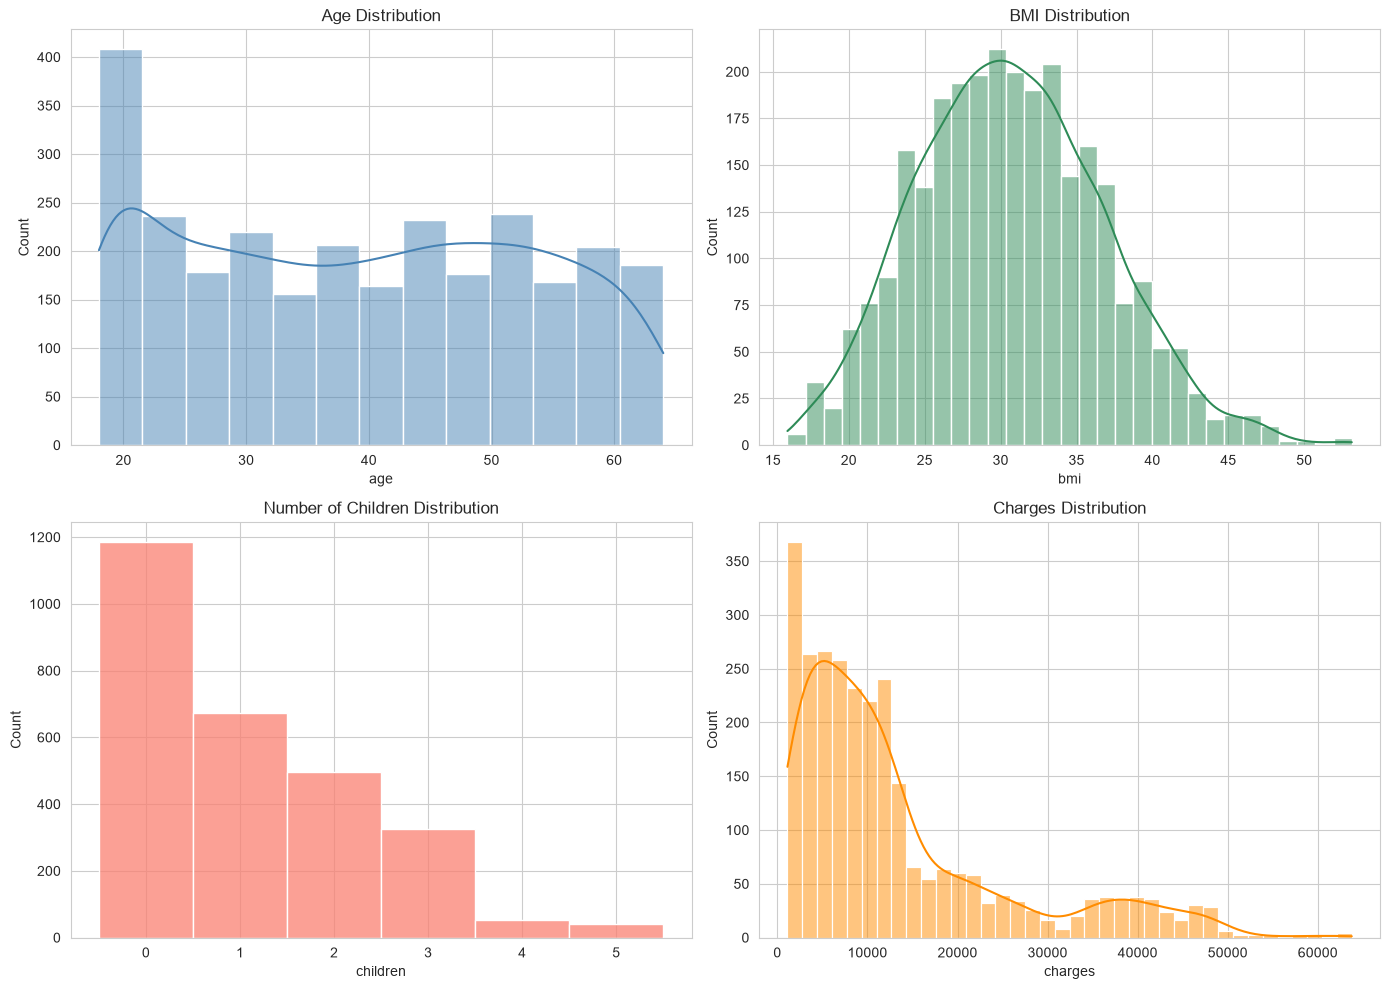

In [32]:
fig, axes = plt.subplots(2, 2, figsize = (14, 10))
sns.histplot(df["age"], kde = True, ax = axes[0, 0], color = "steelblue")
axes[0, 0].set_title("Age Distribution")
sns.histplot(df["bmi"], kde = True, ax = axes[0, 1], color = "seagreen")
axes[0, 1].set_title("BMI Distribution")
sns.histplot(df["children"], discrete = True, ax = axes[1, 0], color = "salmon")
axes[1, 0].set_title("Number of Children Distribution")
sns.histplot(df["charges"], kde = True, ax = axes[1, 1], color = "darkorange")
axes[1, 1].set_title("Charges Distribution")
plt.tight_layout()
plt.show()

In [34]:
for col in ["bmi", "charges"]:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: bounds = ({lower:.1f}, {upper:.1f}, outliers = {n_out} ({n_out / len(df) * 100:.1f} %))")

bmi: bounds = (13.4, 47.6, outliers = 14 (0.5 %))
charges: bounds = (-13147.2, 34412.8, outliers = 296 (10.7 %))


In [35]:
df.groupby("smoker")["charges"].agg(["mean", "median", "std", "count"])

,mean,median,std,count
smoker,,,,
no,8417.874411,7341.4160,6015.568209,2208
yes,32223.139764,34725.8811,11521.258969,564


In [36]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "underweight"
    elif bmi < 25:
        return "normal"
    elif bmi < 30:
        return "overweight"
    else:
        return "obese"

In [38]:
df["bmi_category"] = df["bmi"].apply(bmi_category)

In [39]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,overweight
1,18,male,33.770,1,no,southeast,1725.55230,obese
2,28,male,33.000,3,no,southeast,4449.46200,obese
3,33,male,22.705,0,no,northwest,21984.47061,normal
4,32,male,28.880,0,no,northwest,3866.85520,overweight


In [41]:
df["bmi_category"].value_counts()

bmi_category
obese          1470
overweight      790
normal          472
underweight      40
Name: count, dtype: int64

In [43]:
df.groupby("bmi_category")["charges"].mean().sort_values().round(3)

bmi_category
underweight     8852.201
normal         10218.519
overweight     11015.813
obese          15565.167
Name: charges, dtype: float64

In [46]:
df["log_charges"] = np.log1p(df["charges"])

In [47]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,overweight,9.734236
1,18,male,33.770,1,no,southeast,1725.55230,obese,7.453882
2,28,male,33.000,3,no,southeast,4449.46200,obese,8.400763
3,33,male,22.705,0,no,northwest,21984.47061,normal,9.998137
4,32,male,28.880,0,no,northwest,3866.85520,overweight,8.260455


In [48]:
print(df["charges"].skew(), df["log_charges"].skew())

1.511315043602352 -0.08880519272939949


In [49]:
df_model = pd.get_dummies(
    df,
    columns = ["sex", "smoker", "region", "bmi_category"],
    drop_first = True
)

In [50]:
print(df_model.columns.to_list())

['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_obese', 'bmi_category_overweight', 'bmi_category_underweight']


In [53]:
feature_cols = [c for c in df_model.columns if c not in ["charges", "log_charges"]]
X = df_model[feature_cols]
y = df_model["log_charges"]

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2)

In [68]:
y_test_real = np.expm1(y_test)
candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forerest": RandomForestRegressor(n_estimators = 300, max_depth = 6, n_jobs = -1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators = 300, max_depth = 3, learning_rate = 0.05)
}
trained_models = {}
metrics_rows = []

In [75]:
for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)
    r2 = r2_score(y_test_real, y_pred)
    mae = mean_absolute_error(y_test_real, y_pred)
    rmse = np.sqrt(mean_absolute_error(y_test_real, y_pred))
    trained_models[name] = model
    metrics_rows.append({"Model": name, "R2": r2, "MAE": mae, "RMSE": rmse})
    print(f"[{name}] --> [[R2: {r2:.4f}] - [MAE {mae:.2f}] - [RMSE: {rmse:.2f}]]")

[Linear Regression] --> [[R2: 0.4959] - [MAE 4288.52] - [RMSE: 65.49]]
[Random Forerest] --> [[R2: 0.8992] - [MAE 1725.74] - [RMSE: 41.54]]
[Gradient Boosting] --> [[R2: 0.8950] - [MAE 1832.29] - [RMSE: 42.81]]


In [76]:
results = pd.DataFrame(metrics_rows).sort_values("R2", ascending = False).reset_index(drop = True)

In [77]:
results.round(4)

,Model,R2,MAE,RMSE
0,Random Forerest,0.8992,1725.7442,41.5421
1,Random Forerest,0.8992,1721.8437,41.4951
2,Random Forerest,0.8991,1715.9045,41.4235
3,Gradient Boosting,0.8950,1832.2879,42.8052
4,Gradient Boosting,0.8950,1832.2879,42.8052
5,Gradient Boosting,0.8950,1832.2879,42.8052
6,Linear Regression,0.4959,4288.5175,65.4868
7,Linear Regression,0.4959,4288.5175,65.4868
8,Linear Regression,0.4959,4288.5175,65.4868


In [78]:
best_model_name = results.loc[0, "Model"]
best_model = trained_models[best_model_name]

In [79]:
best_model_name

'Random Forerest'

In [80]:
best_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal 

In [85]:
joblib.dump(best_model, "insurance_model.pkl")
joblib.dump(feature_cols, "model_features.pkl")
joblib.dump(best_model_name, "model_name.pkl")

['model_name.pkl']